# Growth at the top, erosion at the bottom

### How the distribution of U.S. family income moved between 1972 and 2016

**Research question.** The headline U.S. income series is usually quoted as a single number — the
median. But a median says nothing about the shape of the distribution around it. This project asks:

> Between 1972 and 2016, did U.S. family incomes grow, stagnate, or spread apart — and how much of
> the change is accounted for by education?

**Why it matters.** If the bottom of the distribution falls while the top is flat, a stagnant median
is not "no change"; it is a redistribution. The distinction changes how survey evidence should be read.

**Data.** General Social Survey (GSS), 1972–2016, more than 55,000 respondents with valid family income.
The extract, its provenance and its reuse terms are documented in `data/README.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})

DATA = Path("data/gss_income.csv")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.3.5


## 1. The data

One row per respondent. `realinc` is the GSS family-income variable already expressed in constant
dollars, so values are comparable across survey years without further deflation.

| Variable | Meaning |
|---|---|
| `year` | survey year (31 waves, 1972–2016) |
| `realinc` | family income, constant dollars |
| `degree` | highest degree: 0 = less than high school, 1 = high school, 2 = junior college, 3 = bachelor's, 4 = graduate |
| `educ` | years of schooling |
| `wtssall` | GSS person weight (corrects for subsampling and non-response) |

In [2]:
df = pd.read_csv(DATA)
print(f"rows: {len(df):,}   columns: {df.shape[1]}")
print(f"survey years: {df.year.min():.0f}-{df.year.max():.0f}")
df[["year", "realinc", "degree", "educ", "wtssall"]].head()

rows: 55,343   columns: 5
survey years: 1972-2016


,year,realinc,degree,educ,wtssall
0,1972,13537.0,3,18.0,0.9
1,1972,18951.0,1,12.0,0.4
2,1972,30458.0,1,12.0,1.3
3,1972,37226.0,1,14.0,0.9
4,1972,30458.0,1,12.0,0.9


## 2. Method

Three decisions drive every number below.

**Survey weights.** GSS samples are not self-weighting: some years over-sample particular groups.
Ignoring `wtssall` biases any aggregate toward over-sampled respondents, so all statistics here are
weighted, using a weighted quantile that interpolates on the mid-point of the cumulative weight.

**Constant dollars.** `realinc` is already deflated, so a dollar in 1972 and a dollar in 2016 are the
same unit. No further adjustment is applied.

**The top code.** GSS income is collected in brackets, and the open-ended top bracket is assigned a
single value. That value is the maximum observed in each survey year, and it absorbs a large number
of respondents — enough that an unadjusted 90th percentile lands *inside* the censored mass. Every
tail statistic below is therefore computed on a **trimmed sample** that drops observations sitting on
their survey year's ceiling; medians and lower quantiles are unaffected by the trim.

In [3]:
def weighted_quantile(values, weights, q):
    """Weighted quantile via linear interpolation on cumulative mid-weights."""
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(v, kind="mergesort")
    v, w = v[order], w[order]
    cum = np.cumsum(w) - 0.5 * w
    cum /= w.sum()
    return float(np.interp(q, cum, v))


def weighted_gini(values, weights):
    """Gini coefficient from the weighted Lorenz curve."""
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(v, kind="mergesort")
    v, w = v[order], w[order]
    p = np.cumsum(w) / w.sum()
    L = np.cumsum(w * v) / (w * v).sum()
    p = np.concatenate(([0.0], p))
    L = np.concatenate(([0.0], L))
    return float(1.0 - np.sum((p[1:] - p[:-1]) * (L[1:] + L[:-1])))


year_max = df.groupby("year")["realinc"].transform("max")
df["topcoded"] = df["realinc"] >= year_max - 1e-6

print(f"observations on their year's top code: {df.topcoded.sum():,} "
      f"({100 * df.topcoded.mean():.1f}% of the sample)")
print(df.groupby(df.year.floordiv(10).mul(10))["topcoded"].mean().mul(100).round(1)
      .rename("share_topcoded_%").to_string())

observations on their year's top code: 5,267 (9.5% of the sample)
year
1970     7.4
1980    10.0
1990    11.3
2000     9.2
2010     9.1


## 3. Seeing the whole distribution move

Income is multiplicative: the gap between \$20,000 and \$40,000 is the same proportional step as the
gap between \$50,000 and \$100,000, so a log axis is the honest way to draw it. A cumulative
distribution avoids binning altogether — every observation contributes, and the vertical position of
the curve reads directly as "this share of the population earns less than this".

Placing the first period and the last period on the same axes shows that the shift was **not a
translation**: the lower half of the curve moved left, the upper tail barely moved, and the two
curves cross near the 90th percentile.

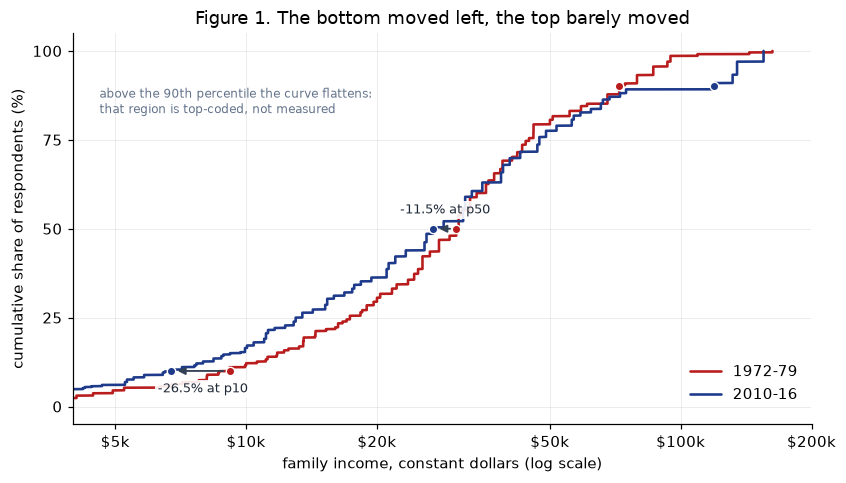

In [4]:
def weighted_ecdf(values, weights):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(v, kind="mergesort")
    v, w = v[order], w[order]
    return v, np.cumsum(w) / w.sum()


periods = [(1972, 1979, "1972-79", "#b91c1c"), (2010, 2016, "2010-16", "#1e3a8a")]
quantiles = [0.10, 0.50, 0.90]
marks = {}

fig, ax = plt.subplots(figsize=(7.8, 4.5))
for lo, hi, label, colour in periods:
    d = df[(df.year >= lo) & (df.year <= hi)]
    v, c = weighted_ecdf(d.realinc, d.wtssall)
    ax.plot(v / 1e3, c * 100, color=colour, linewidth=1.7, label=label, solid_capstyle="round")
    marks[label] = [weighted_quantile(d.realinc, d.wtssall, q) for q in quantiles]
    for q, val in zip(quantiles, marks[label]):
        ax.plot([val / 1e3], [q * 100], marker="o", markersize=5.5, color=colour,
                markeredgecolor="white", markeredgewidth=0.9, zorder=5)

for q, old, new in zip(quantiles[:2], marks["1972-79"], marks["2010-16"]):
    ax.annotate("", xy=(new / 1e3, q * 100), xytext=(old / 1e3, q * 100),
                arrowprops=dict(arrowstyle="-|>", color="#334155", linewidth=1.2,
                                shrinkA=4, shrinkB=4))
    ax.annotate(f"{100 * (new / old - 1):+.1f}% at p{int(q * 100)}",
                xy=((old + new) / 2 / 1e3, q * 100), xytext=(0, -14 if q < .5 else 10),
                textcoords="offset points", ha="center", fontsize=8.5, color="#1f2937",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=1.5))

ax.set_xscale("log")
ax.set_xlim(4, 200)
ax.set_xticks([5, 10, 20, 50, 100, 200])
ax.set_xticklabels(["$5k", "$10k", "$20k", "$50k", "$100k", "$200k"])
ax.minorticks_off()
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("family income, constant dollars (log scale)")
ax.set_ylabel("cumulative share of respondents (%)")
ax.set_title("Figure 1. The bottom moved left, the top barely moved")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 0.02))
ax.text(4.6, 90, "above the 90th percentile the curve flattens:\nthat region is top-coded, not measured",
        fontsize=8, color="#64748b", va="top")

fig.tight_layout()
fig.savefig(FIG / "fig1_income_cdf_1970s_vs_2010s.png", bbox_inches="tight")
plt.show()

## 4. The middle fell, the tails moved apart

Pooling survey years into five periods and taking weighted quantiles of `realinc` shows where the
distribution moved. The pattern is not a uniform shift: the bottom decile lost about a quarter of its
real income, the median lost about a tenth, and the upper quartile barely moved.

In [5]:
DECADES = [(1972, 1979, "1972-79"), (1980, 1989, "1980s"), (1990, 1999, "1990s"),
           (2000, 2009, "2000s"), (2010, 2016, "2010s")]

rows = []
for lo, hi, label in DECADES:
    d = df[(df.year >= lo) & (df.year <= hi)]
    t = d[~d.topcoded]
    rows.append({
        "decade": label,
        "n": len(d),
        "p10": weighted_quantile(d.realinc, d.wtssall, .10),
        "p25": weighted_quantile(d.realinc, d.wtssall, .25),
        "median": weighted_quantile(d.realinc, d.wtssall, .50),
        "p75": weighted_quantile(d.realinc, d.wtssall, .75),
        "p90": weighted_quantile(t.realinc, t.wtssall, .90),
    })

dec = pd.DataFrame(rows).set_index("decade")
dec["p75_p25"] = dec.p75 / dec.p25

summary = dec[["n", "p10", "p25", "median", "p75", "p90"]].round(0).astype(int)
summary["p75/p25"] = dec.p75_p25.round(2)
summary

,n,p10,p25,median,p75,p90,p75/p25
decade,,,,,,,
1972-79,9743,9167,17335,30458,44782,55515,2.58
1980s,12854,7238,14515,26538,44863,48277,3.09
1990s,11590,8156,16235,28650,46507,48938,2.86
2000s,12802,8302,17207,31268,51620,56850,3.00
2010s,8354,6738,13475,26950,47300,56160,3.51


In [6]:
first, last = dec.iloc[0], dec.iloc[-1]
change = pd.DataFrame({
    "1972-79": first[["p10", "p25", "median", "p75", "p90"]],
    "2010s": last[["p10", "p25", "median", "p75", "p90"]],
})
change["change_%"] = (change["2010s"] / change["1972-79"] - 1).mul(100)
print(f"ratio p75/p25: {first.p75_p25:.2f} -> {last.p75_p25:.2f}")
change.assign(**{"1972-79": change["1972-79"].round(0).astype(int),
                 "2010s": change["2010s"].round(0).astype(int),
                 "change_%": change["change_%"].round(1)})

ratio p75/p25: 2.58 -> 3.51


,1972-79,2010s,change_%
p10,9167,6738,-26.5
p25,17335,13475,-22.3
median,30458,26950,-11.5
p75,44782,47300,5.6
p90,55515,56160,1.2


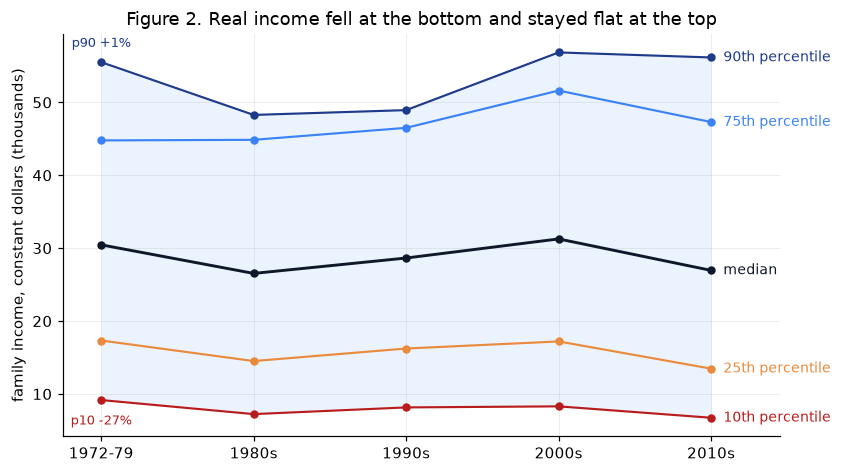

In [7]:
series = [
    ("p10", "#b91c1c", "10th percentile"),
    ("p25", "#ea8a3c", "25th percentile"),
    ("median", "#0f172a", "median"),
    ("p75", "#3b82f6", "75th percentile"),
    ("p90", "#1e3a8a", "90th percentile"),
]
x = np.arange(len(dec))

fig, ax = plt.subplots(figsize=(7.8, 4.4))
ax.fill_between(x, dec.p10 / 1e3, dec.p90 / 1e3, color="#dbeafe", alpha=0.55, linewidth=0)
for col, colour, label in series:
    ax.plot(x, dec[col] / 1e3, marker="o", markersize=4.5, linewidth=1.9 if col == "median" else 1.4,
            color=colour, label=label)
    ax.annotate(label, xy=(x[-1], dec[col].iloc[-1] / 1e3), xytext=(8, 0),
                textcoords="offset points", color=colour, fontsize=9, va="center")

ax.set_xticks(x)
ax.set_xticklabels(dec.index)
ax.set_xlim(-0.25, len(dec) - 0.55)
ax.set_ylabel("family income, constant dollars (thousands)")
ax.set_title("Figure 2. Real income fell at the bottom and stayed flat at the top")
ax.annotate(f"p10 {change.loc['p10','change_%']:+.0f}%", xy=(x[0], dec.p10.iloc[0] / 1e3),
            xytext=(0, -16), textcoords="offset points", fontsize=8.5, color="#b91c1c", ha="center")
ax.annotate(f"p90 {change.loc['p90','change_%']:+.0f}%", xy=(x[0], dec.p90.iloc[0] / 1e3),
            xytext=(0, 10), textcoords="offset points", fontsize=8.5, color="#1e3a8a", ha="center")

fig.tight_layout()
fig.savefig(FIG / "fig2_income_quantiles_by_decade.png", bbox_inches="tight")
plt.show()

## 5. Measuring how far apart the tails moved

Two complementary summaries, both on the trimmed sample:

* the **Gini coefficient**, an overall index of inequality between 0 (equal) and 1 (one household
  holds everything);
* the **standard deviation of log income**, which measures proportional dispersion and matches the
  multiplicative structure of the data.

Both are lower bounds: the censored top tail is excluded, which removes precisely the observations
that would push them higher.

In [8]:
rows = []
for lo, hi, label in DECADES:
    d = df[(df.year >= lo) & (df.year <= hi)]
    t = d[~d.topcoded]
    logs = np.log(t.realinc)
    rows.append({
        "decade": label,
        "gini": weighted_gini(t.realinc, t.wtssall),
        "sd_log": float(np.sqrt(np.average((logs - np.average(logs, weights=t.wtssall)) ** 2,
                                           weights=t.wtssall))),
        "below_60pct_median": 100 * np.average(d.realinc < .6 * weighted_quantile(d.realinc, d.wtssall, .5),
                                               weights=d.wtssall),
    })

ineq = pd.DataFrame(rows).set_index("decade")
ineq.round(3)

,gini,sd_log,below_60pct_median
decade,,,
1972-79,0.326,0.767,25.517
1980s,0.335,0.823,27.588
1990s,0.330,0.838,28.470
2000s,0.348,0.933,29.052
2010s,0.378,0.997,31.156


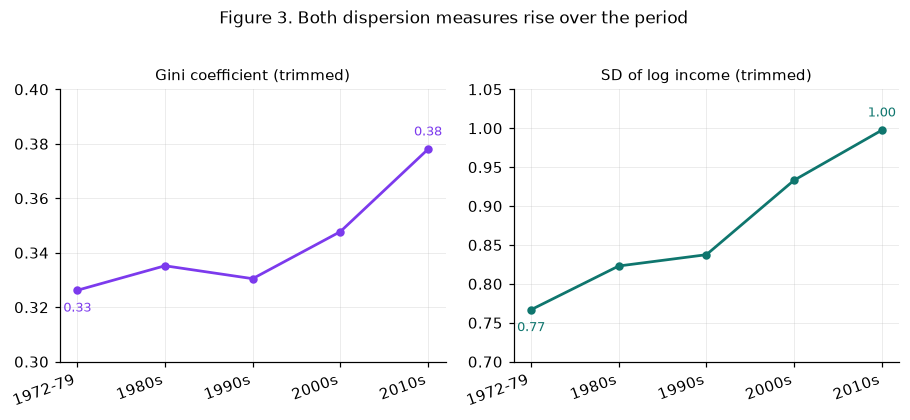

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.7), sharex=True)
panels = [("gini", "Gini coefficient (trimmed)", "#7c3aed", (0.30, 0.40)),
          ("sd_log", "SD of log income (trimmed)", "#0f766e", (0.70, 1.05))]

for ax, (col, title, colour, ylim) in zip(axes, panels):
    ax.plot(x, ineq[col], marker="o", markersize=4.5, linewidth=1.8, color=colour)
    ax.set_ylim(*ylim)
    ax.set_xticks(x)
    ax.set_xticklabels(ineq.index, rotation=20, ha="right")
    ax.set_title(title, fontsize=10)
    ax.annotate(f"{ineq[col].iloc[0]:.2f}", xy=(0, ineq[col].iloc[0]), xytext=(0, -14),
                textcoords="offset points", ha="center", fontsize=8.5, color=colour)
    ax.annotate(f"{ineq[col].iloc[-1]:.2f}", xy=(x[-1], ineq[col].iloc[-1]), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=8.5, color=colour)

fig.suptitle("Figure 3. Both dispersion measures rise over the period", y=1.02, fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "fig3_inequality_by_decade.png", bbox_inches="tight")
plt.show()

## 6. Education is the main divider

Splitting the same respondents by highest degree shows that the aggregate stagnation is a
composition of two opposite trends: median income fell by roughly a third for respondents without a
high-school diploma and rose for graduates, while the bachelor's-to-high-school ratio widened from
about 1.3 to 1.8.

In [10]:
DEGREE = {0: "Less than HS", 1: "High school", 2: "Junior college", 3: "Bachelor's", 4: "Graduate"}

rows = []
for lo, hi, label in DECADES:
    d = df[(df.year >= lo) & (df.year <= hi)]
    rec = {"decade": label}
    for k, name in DEGREE.items():
        s = d[d.degree == k]
        rec[name] = weighted_quantile(s.realinc, s.wtssall, .50)
    rows.append(rec)

edu = pd.DataFrame(rows).set_index("decade")
edu["BA_premium"] = edu["Bachelor's"] / edu["High school"]

edu_out = edu.copy()
edu_out[list(DEGREE.values())] = edu_out[list(DEGREE.values())].round(0).astype(int)
edu_out["BA_premium"] = edu.BA_premium.round(2)
edu_out

,Less than HS,High school,Junior college,Bachelor's,Graduate,BA_premium
decade,,,,,,
1972-79,20355,32761,38449,43994,50027,1.34
1980s,16577,28030,33016,38222,51023,1.36
1990s,15668,27188,31005,39919,51570,1.47
2000s,14860,28156,38374,44887,56850,1.59
2010s,13475,25740,31590,46800,56160,1.82


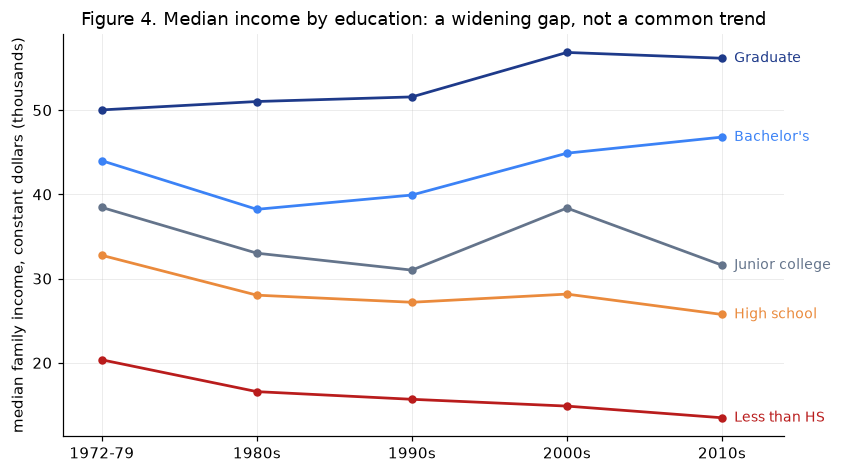

In [11]:
colours = ["#b91c1c", "#ea8a3c", "#64748b", "#3b82f6", "#1e3a8a"]

fig, ax = plt.subplots(figsize=(7.8, 4.4))
for colour, name in zip(colours, DEGREE.values()):
    ax.plot(x, edu[name] / 1e3, marker="o", markersize=4.5, linewidth=1.8, color=colour, label=name)
    ax.annotate(name, xy=(x[-1], edu[name].iloc[-1] / 1e3), xytext=(8, 0),
                textcoords="offset points", color=colour, fontsize=9, va="center")

ax.set_xticks(x)
ax.set_xticklabels(edu.index)
ax.set_xlim(-0.25, len(edu) - 0.6)
ax.set_ylabel("median family income, constant dollars (thousands)")
ax.set_title("Figure 4. Median income by education: a widening gap, not a common trend")

fig.tight_layout()
fig.savefig(FIG / "fig4_median_by_education.png", bbox_inches="tight")
plt.show()

## 7. Findings and limitations

**Findings.**

1. **The bottom lost ground.** The 10th percentile fell from about \$9,200 to \$6,700 in constant
   dollars (−26.5%), and the 25th percentile fell 22.3%. A falling median is therefore not
   a measurement artefact — the lower half of the distribution genuinely moved left.
2. **The top did not gain much either — it held.** The 90th percentile, measured after trimming the
   censored top code, moved only +1.2% over four decades.
3. **But the gap widened.** The p75/p25 ratio rose from 2.58 to 3.51, the Gini from 0.33 to 0.38, and
   the SD of log income from 0.77 to 1.00. The share of respondents below 60% of their decade's
   median rose from 25.5% to 31.2%.
4. **Education separates the trends.** Median income for respondents without a high-school diploma
   fell 33.8%, while bachelor's-degree respondents gained 6.4% and graduates 12.3%. The
   bachelor's-to-high-school premium widened from 1.34 to 1.82.

**One limitation, stated plainly.** The GSS income question is bracketed and top-coded, and the
ceiling absorbs 7–11% of respondents in each period. Those observations are censored, not observed,
so every tail statistic here — p90, the Gini, the SD of log income — is a **lower bound** on true
inequality. The direction of the result is robust to this (dropping or keeping the top code changes
the level, not the trend), but the magnitude is not.

**Other caveats worth recording.**

* These are repeated cross-sections, not a panel: the same households are not followed, so decade
  differences mix real change with changes in who was sampled.
* `realinc` is *family* income and is not equivalised for household size. Households became smaller
  over the period, which biases the comparison in an unquantified direction.
* Income refers to the year before the interview and is self-reported; 11.2% of GSS respondents have
  no valid income value and are excluded, which is unlikely to be missing at random.
* The extract ends in 2016, so nothing here speaks to the post-2016 period.